In [214]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [215]:
df = pd.read_csv('marketing.csv')
df.columns = df.columns.str.strip()

In [216]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510.0,Male,19.0,19000.0,0.0
1,15810944.0,Male,35.0,20000.0,0.0
2,15668575.0,Female,26.0,43000.0,0.0
3,15603246.0,Female,27.0,57000.0,0.0
4,15804002.0,Male,19.0,76000.0,0.0


---

## 4. Data Pre-Processing

### 4.1 Memeriksa Missing Value dan Duplikat Data

In [217]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [218]:
df.duplicated().sum()

np.int64(0)

### 4.2 Menghapus Kolom User Id

In [219]:
data_bersih = df.drop(columns=['User ID'])

print("Kolom saat ini:", data_bersih.columns.tolist())

Kolom saat ini: ['Gender', 'Age', 'EstimatedSalary', 'Purchased']


### 4.3 Mengubah Kolom Gender yang Berisi Teks Menjadi Angka Biner

In [220]:
gender = data_bersih['Gender'].astype(str).str.strip().str.lower()
data_bersih['Gender'] = np.where(gender == 'male', 1, 0)

print(data_bersih['Gender'].head())

0    1
1    1
2    0
3    0
4    1
Name: Gender, dtype: int64


### 4.4 Memisahkan Fitur ($X$) dan Target ($y$)

In [221]:
X = data_bersih.drop(columns=['Purchased'])
y = data_bersih['Purchased'].astype(int)

print("Fitur (X) :", X.columns.tolist())
print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {len(y)} label jawaban")

Fitur (X) : ['Gender', 'Age', 'EstimatedSalary']
Bentuk X : 400 baris, 3 kolom
Bentuk y : 400 label jawaban


### 4.5 Pembagian Data Latih dan Data Uji (80% : 20%)

In [222]:
np.random.seed(43)

indeks_acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[indeks_acak[:batas]].reset_index(drop=True)
X_test = X.iloc[indeks_acak[batas:]].reset_index(drop=True)

y_train = y.iloc[indeks_acak[:batas]].reset_index(drop=True)
y_test = y.iloc[indeks_acak[batas:]].reset_index(drop=True)

print(f"Data Latih : {len(X_train)} baris (80%)")
print(f"Data Uji : {len(X_test)} baris (20%)")

Data Latih : 320 baris (80%)
Data Uji : 80 baris (20%)


## 5. Modelling Naive Bayes

### 5.1 Menghitung Prior Probability ($P$($y$))

In [223]:
total = len(y_train)

tidak_beli = (y_train == 0).sum()
beli = (y_train == 1).sum()

prior_0 = tidak_beli / total
prior_1 = beli / total

print(f"Total Data Latih            : {total}")
print(f"Jumlah yang Tidak Membeli   : {tidak_beli} orang")
print(f"Jumlah yang Membeli         : {beli} orang")

print(f"Prior Tidak Beli            : {prior_0:.3f}")
print(f"Prior Beli                  : {prior_1:.3f}")


Total Data Latih            : 320
Jumlah yang Tidak Membeli   : 216 orang
Jumlah yang Membeli         : 104 orang
Prior Tidak Beli            : 0.675
Prior Beli                  : 0.325


### 5.2 Menghitung Likelihood Training (Parameter Fitur)

In [224]:
mean_age_0 =  X_train.loc[y_train == 0, 'Age'].mean()
var_age_0 = X_train.loc[y_train == 0, 'Age'].var()

mean_sal_0 = X_train.loc[y_train == 0, 'EstimatedSalary'].mean()
var_sal_0 = X_train.loc[y_train == 0, 'EstimatedSalary'].var()

mean_age_1 = X_train.loc[y_train == 1, 'Age'].mean()
var_age_1 = X_train.loc[y_train == 1, 'Age'].var()

mean_sal_1 = X_train.loc[y_train == 1, 'EstimatedSalary'].mean()
var_sal_1 = X_train.loc[y_train == 1, 'EstimatedSalary'].var()

p_male_0 = (X_train.loc[y_train == 0, 'Gender'] == 1).mean()
p_female_0 = 1 - p_male_0

p_male_1 = (X_train.loc[y_train == 1, 'Gender'] == 1).mean()
p_female_1 = 1 - p_male_1

print("--- Kelompok Tidak Beli ---")
print(f"Rata-rata Usia      : {mean_age_0:.2f} tahun (Tingkat Sebaran Data: {var_age_0:.2f})")
print(f"Rata-rata Gaji      : {mean_sal_0:.2f} (Tingkat Sebaran Data: {var_sal_0:.2f})")
print(f"Perbandingan Gender : Pria = {p_male_0:.2%}, Wanita = {p_female_0:.2%}")

print("\n--- Kelompok Beli ---")
print(f"Rata-rata Usia      : {mean_age_1:.2f} tahun (Tingkat Sebaran Data: {var_age_1:.2f})")
print(f"Rata-rata Gaji      : {mean_sal_1:.2f} (Tingkat Sebaran Data: {var_sal_1:.2f})")
print(f"Perbandingan Gender : Pria = {p_male_1:.2%}, Wanita = {p_female_1:.2%}")

--- Kelompok Tidak Beli ---
Rata-rata Usia      : 33.16 tahun (Tingkat Sebaran Data: 64.84)
Rata-rata Gaji      : 60365.74 (Tingkat Sebaran Data: 577126076.66)
Perbandingan Gender : Pria = 50.93%, Wanita = 49.07%

--- Kelompok Beli ---
Rata-rata Usia      : 45.60 tahun (Tingkat Sebaran Data: 76.20)
Rata-rata Gaji      : 85019.23 (Tingkat Sebaran Data: 1854679238.24)
Perbandingan Gender : Pria = 50.96%, Wanita = 49.04%


### 5.3 Menghitung Posterior Probability (Nilai Akhir)

In [225]:
def hitung_gaussian(x, mean, var):
    bagi = np.sqrt(2 * np.pi * var)
    pangkat = np.exp(-((x - mean) ** 2) / (2 * var))
    return (1.0 / bagi) * pangkat

def hitung_posterior(gender, age, salary):
    p_gender_0 = p_male_0 if gender == 1 else p_female_0
    p_age_0 = hitung_gaussian(age, mean_age_0, var_age_0)
    p_sal_0 = hitung_gaussian(salary, mean_sal_0, var_sal_0)

    skor_0 = prior_0 * p_gender_0 * p_age_0 * p_sal_0

    p_gender_1 = p_male_1 if gender == 1 else p_female_1
    p_age_1 = hitung_gaussian(age, mean_age_1, var_age_1)
    p_sal_1 = hitung_gaussian(salary, mean_sal_1, var_sal_1)

    skor_1 = prior_1 * p_gender_1 * p_age_1 * p_sal_1

    return skor_0, skor_1

anonymous = X_test.iloc[0]
skor_tidak_beli, skor_beli = hitung_posterior(anonymous['Gender'], anonymous['Age'], anonymous['EstimatedSalary'])

print(f"Data Pengguna   : Gender = {int(anonymous['Gender'])}, Umur = {anonymous['Age']:.0f}, Gaji = {anonymous['EstimatedSalary']:.0f}")
print(f"Skor Tidak Beli : {skor_tidak_beli:.10e}")
print(f"Skor Beli       : {skor_beli:.10e}")

Data Pengguna   : Gender = 0, Umur = 34, Gaji = 25000
Skor Tidak Beli : 9.1719013047e-08
Skor Beli       : 1.0572439390e-08


### 5.4 Memberikan Keputusan Prediksi dengan Membandingkan Skor($y$ = 1) dan Skor($y$ = 0)

In [226]:
y_pred = []

for i in range(len(X_test)):
    baris = X_test.iloc[i]

    skor_0, skor_1 = hitung_posterior(baris['Gender'], baris['Age'], baris['EstimatedSalary'])

    tebakan = 1 if skor_1 > skor_0 else 0
    y_pred.append(tebakan)

y_pred = np.array(y_pred)

print("Hasil 10 Tebakan Model   :", y_pred[:10])
print("Kunci Jawaban Asli       :", y_test.iloc[:10].values)

Hasil 10 Tebakan Model   : [0 0 0 0 1 1 0 0 0 0]
Kunci Jawaban Asli       : [0 0 0 0 1 1 0 1 0 0]


## 6. Evaluation

### 6.1 Membentuk Tabel Matriks Evaluasi

In [227]:
y_true = y_test.values

TP = int(((y_pred == 1) & (y_true == 1)).sum())
TN = int(((y_pred == 0) & (y_true == 0)).sum()) 
FP = int(((y_pred == 1) & (y_true == 0)).sum()) 
FN = int(((y_pred == 0) & (y_true == 1)).sum())  

tabel = pd.DataFrame(
    data=[[TN, FP], [FN, TP]],
    index=['Fakta: Tidak Beli', 'Fakta: Beli'],
    columns=['Prediksi: Tidak Beli', 'Prediksi: Beli']
)

print(f"TP: {TP} | TN: {TN} | FP: {FP} | FN: {FN}")
display(tabel)

TP: 33 | TN: 40 | FP: 1 | FN: 6


,Prediksi: Tidak Beli,Prediksi: Beli
Fakta: Tidak Beli,40,1
Fakta: Beli,6,33


### 6.2 Menghitung Metrik Evaluasi Klasifikasi Akurasi

In [228]:
total = TP + TN + FP + FN

akurasi = (TP + TN) / total if total > 0 else 0.0

presisi = TP / (TP + FP) if (TP + FP) > 0 else 0.0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0

f1_score = 2 * (presisi * recall) / (presisi + recall) if (presisi + recall) > 0 else 0.0

print("=== HASIL EVALUASI MODEL ===")
print(f"Akurasi  : {akurasi:.2%}")
print(f"Presisi  : {presisi:.2%}")
print(f"Recall   : {recall:.2%}")
print(f"F1-Score : {f1_score:.2%}")

=== HASIL EVALUASI MODEL ===
Akurasi  : 91.25%
Presisi  : 97.06%
Recall   : 84.62%
F1-Score : 90.41%


### 6.3 Visualisasi Evaluasi Model Naive Bayes: Confusion Matrix dan Performa Metriks

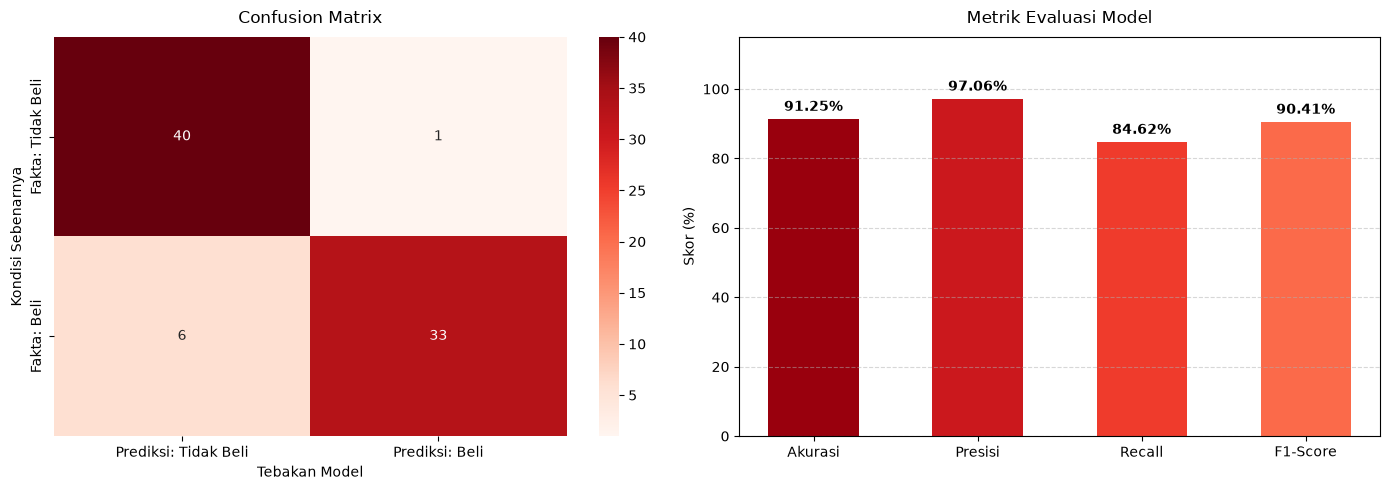

In [233]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(tabel, annot=True, fmt='d', cmap='Reds', cbar=True, ax=axes[0])
axes[0].set_title('Confusion Matrix', fontsize=12, pad=10)
axes[0].set_xlabel('Tebakan Model', fontsize=10)
axes[0].set_ylabel('Kondisi Sebenarnya', fontsize=10)

nama_metrik = ['Akurasi', 'Presisi', 'Recall', 'F1-Score']
nilai_metrik = [akurasi * 100, presisi * 100, recall * 100, f1_score * 100]
warna = ['#99000d', '#cb181d', '#ef3b2c', '#fb6a4a']

batang = axes[1].bar(nama_metrik, nilai_metrik, color=warna, width=0.55)

for b in batang:
    tinggi = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, tinggi + 1.5, f'{tinggi:.2f}%', 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].set_ylim(0, 115)
axes[1].set_title('Metrik Evaluasi Model', fontsize=12, pad=10)
axes[1].set_ylabel('Skor (%)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---

## 7. Conclusion

### 7.1 Kesimpulan Analisis dan Pemodelan

1. Fitur usia (`Age`) dan estimasi gaji (`EstimatedSalary`) menjadi faktor pembeda paling signifikan terhadap keputusan pembelian produk. Nasabah yang memutuskan membeli didominasi oleh kelompok usia lebih matang (rata-rata 45,6 tahun) dengan pendapatan lebih tinggi (rata-rata 85.019), sedangkan faktor jenis kelamin (`Gender`) cenderung terdistribusi seimbang di kedua kelompok.

2. Model Naive Bayes yang dibangun dari dasar (*from scratch*) tanpa pustaka Scikit-Learn menunjukkan performa yang sangat memuaskan pada data uji (80 sampel):
   * **Akurasi (91,25%):** Model mampu memprediksi 73 nasabah dengan benar dari total 80 data uji.
   * **Presisi (97,06%):** Dari seluruh nasabah yang diprediksi akan membeli, hampir seluruhnya (33 dari 34) terbukti merupakan pembeli nyata di lapangan.
   * **Recall (84,62%):** Model berhasil menjaring 33 dari total 39 pembeli nyata tanpa banyak kehilangan target pasar potensial.
   * **F1-Score (90,41%):** Menunjukkan bahwa model memiliki keseimbangan yang sangat baik antara presisi dan sensitivitas deteksi.

3. Dari total 80 data uji, model hanya melakukan 7 kesalahan tebak, yang didominasi oleh 6 kasus *False Negative* (nasabah pembeli yang dikira tidak membeli). Hal ini wajar terjadi pada metode probabilistik sederhana akibat adanya irisan nilai pada rentang usia atau pendapatan tertentu.